# 02. Exploratory analysis

**Question: What patterns in emergency department visits should we consider when building a forecasting model?**

We use data up to 2022 for exploration and model development. The 2023 data are reserved for a final evaluation after the models and evaluation rules have been fixed.

In [148]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import holidays

project_dir = Path.cwd().parent
path = project_dir / "data" / "processed" / "df_cleaned.parquet"

try:
    df = pd.read_parquet(path, filters=[("date", "<", pd.Timestamp("2023-01-01"))])
    # If you've run Notebook 1 all the way through, you shouldn't have any problems with this try
except (FileNotFoundError, ImportError):  # Otherwise, we can reapply the transformations here
    file = project_dir / "data" / "raw" / "emergency-visits-2017-2023.csv"
    df_raw = pd.read_csv(file, sep=";").query("date < '2023-01-01'")
    df_fr = df_raw[df_raw["dep"] == "69"].copy()
    df_fr["date"] = pd.to_datetime(df_fr["date"])
    df_fr = df_fr.sort_values("date")
    df_fr = df_fr.set_index("date")
    df = df_fr.rename(columns={"nb_passages": "visits"})
    df = df[["visits"]]

### 1. How has the number of visits changed over time?

#### Daily visits and moving averages

The raw daily series is noisy, so we add 7-day and 30-day moving averages. The 7-day average smooths the weekly pattern, while the 30-day average highlights longer-term trends and seasonality. The shaded area marks the first COVID-19 lockdown in 2020.

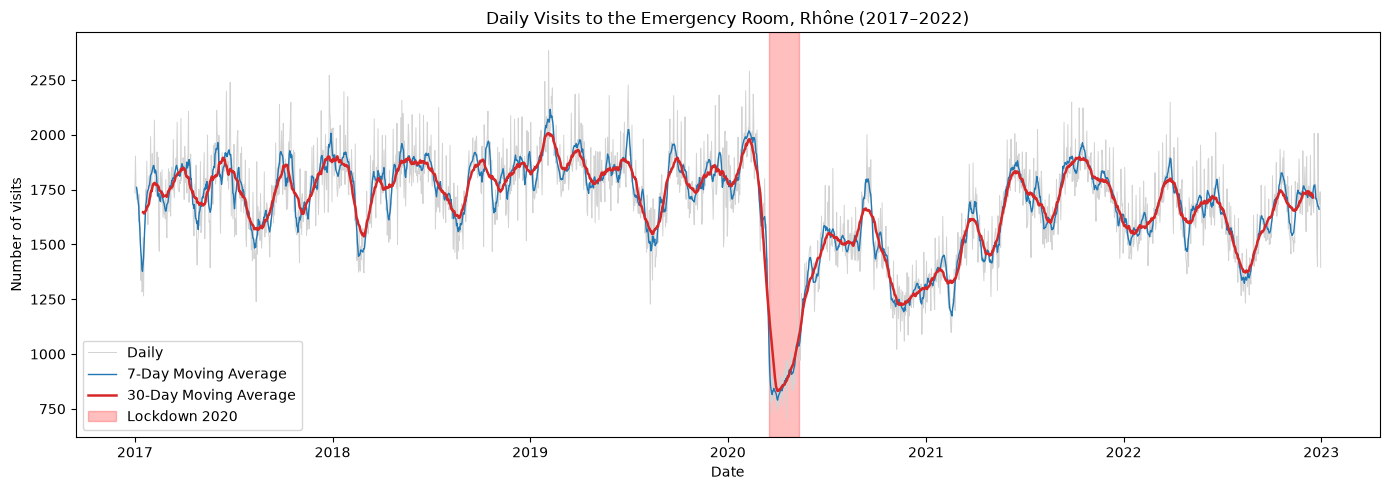

In [126]:
df["ratio_to_year"] = df["visits"] / df.groupby(df.index.year)["visits"].transform("mean")
df["roll_7"] = df["visits"].rolling(window=7, center=True).mean()
df["roll_30"] = df["visits"].rolling(window=30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["visits"], color="lightgrey", linewidth=0.7, label="Daily")
ax.plot(df.index, df["roll_7"], color="tab:blue", linewidth=1, label="7-Day Moving Average")
ax.plot(df.index, df["roll_30"], color="tab:red", linewidth=1.8, label="30-Day Moving Average")

ax.axvspan("2020-03-17", "2020-05-11", color="red", alpha=0.25, label="Lockdown 2020")
ax.set_title("Daily Visits to the Emergency Room, Rhône (2017–2022)")
ax.set_xlabel("Date")
ax.set_ylabel("Number of visits")
ax.legend()
plt.tight_layout()
plt.show()

The raw data reveal significant daily volatility, while the 7- and 30-day moving averages help identify the underlying trend.

Activity remained relatively stable and seasonal until early 2020, with average volumes ranging from 1,700 to 1,800 visits per day. The lockdown period marked a major turning point: there was a sharp collapse in visitor numbers, which fell below 800 visits per day. After this drop, visitor numbers gradually rebounded but remained, over the 2021–2022 period, generally below the levels observed before the health crisis.

### Year-by-year comparison and seasonal patterns

To understand trends within a single year and perhaps identify seasonal patterns, we plot the 30-day moving average of the number of visits for each year, and we aggregate all the data on the same day-of-year axis.

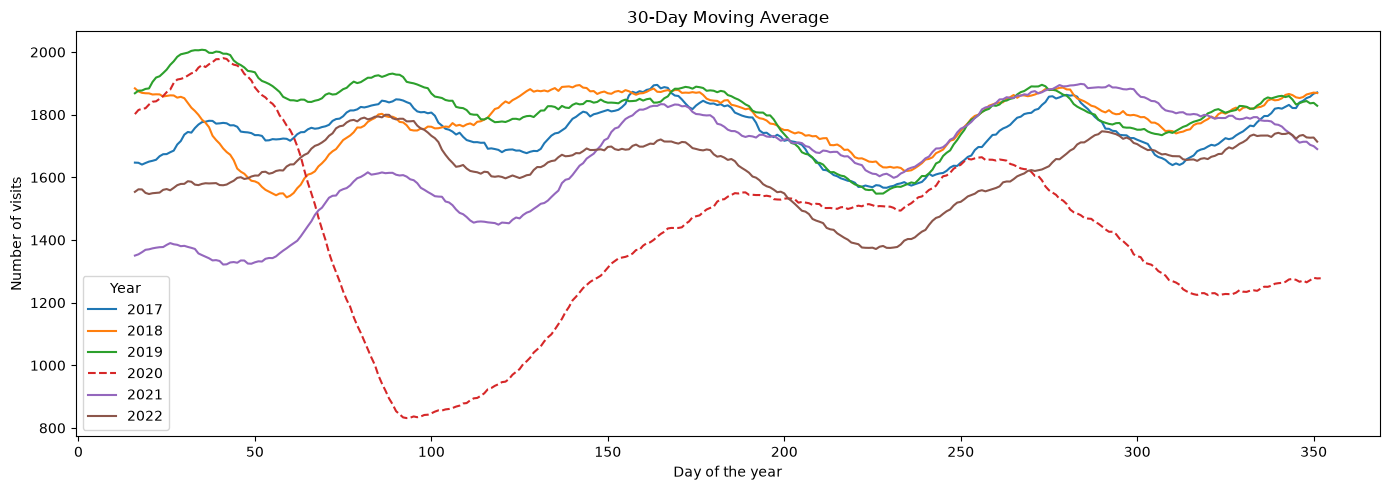

In [121]:
fig, ax = plt.subplots(figsize=(14, 5))

for year, group in df.groupby(df.index.year):
    smooth = group["visits"].rolling(window=30, center=True).mean()
    ax.plot(smooth.index.day_of_year, smooth.values, label=str(year),
            linestyle="--" if year == 2020 else "-")

ax.set_title("30-Day Moving Average")
ax.set_xlabel("Day of the year")
ax.set_ylabel("Number of visits")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

This graph highlights three key findings:

1. A recurring seasonal pattern (excluding 2020): The years 2017, 2018, 2019, 2021, and 2022 show broadly similar trends. Typically, there is a winter trough (between days 50 and 100), followed by a spring uptick and a summer plateau, before another peak in the fall. Visitor numbers generally remain between 1,500 and 1,900 visits per day.

2. The anomaly of 2020 (dotted line): The year 2020 stands out dramatically. While it began in line with previous years, the curve plummeted sharply around day 70 (mid-March), reaching a historic low of approximately 850 visits. The recovery was then slow and gradual, never regaining the levels seen in other years for the remainder of the year.

3. An atypical 2021: The 2021 curve reveals an interesting temporal shift. The usual seasonal trough appears to have shifted and intensified during the summer period (between days 200 and 250, i.e., from late July to early September), reaching levels close to 1,600 visits. While this may suggest a persistent effect of the health crisis, it can also be described as a modification of the usual seasonal profile without directly attributing it to the pandemic.

### Weekly patterns

To complement the analysis of underlying trends, we examined the distribution of visits throughout the week. The following charts show the mean number of visits for each weekday relative to the average of the seven weekday means for that year. The heatmap displays the same ratios.

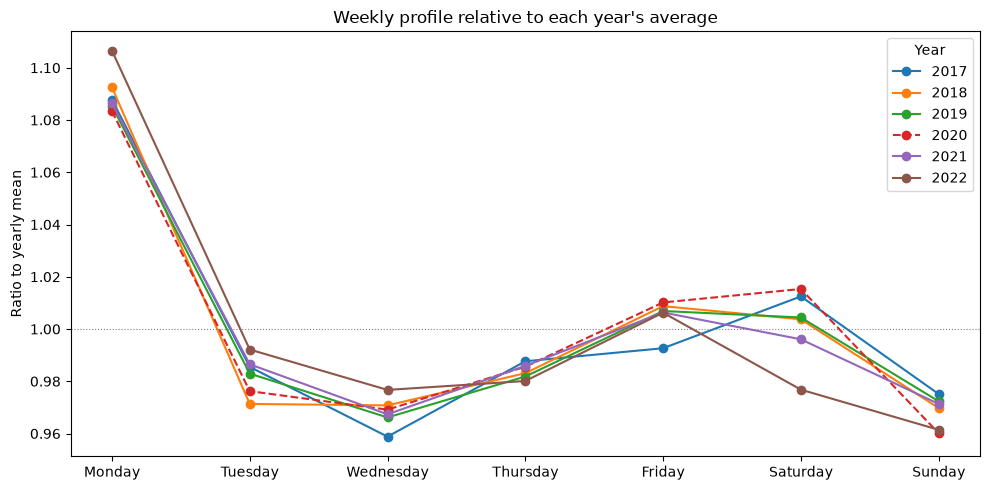

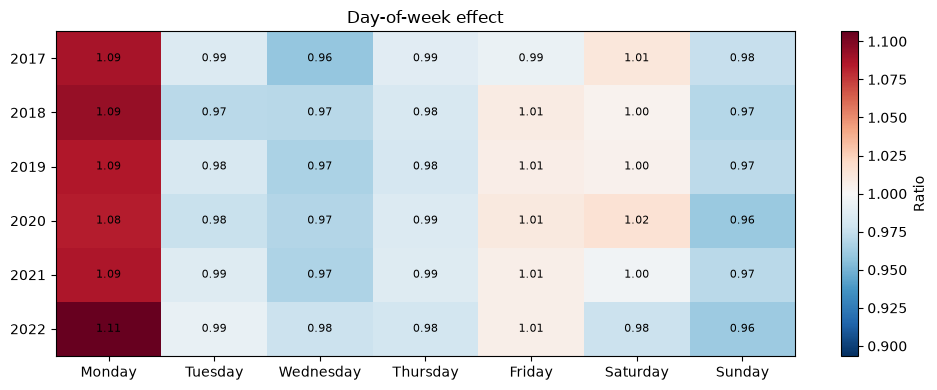

In [127]:
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekly = (
    df["visits"]
    .groupby([df.index.year, df.index.day_name()])
    .mean()
    .unstack()
    [days_order]
)
weekly.index.name = "year"

weekly_norm = weekly.div(weekly.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 5))

for year, row in weekly_norm.iterrows():
    ax.plot(days_order, row.values, marker="o", label=str(year),
            linestyle="--" if year == 2020 else "-")

ax.axhline(1, color="grey", linewidth=0.8, linestyle=":")
ax.set_title("Weekly profile relative to each year's average")
ax.set_ylabel("Ratio to yearly mean")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(weekly_norm.values, cmap="RdBu_r", aspect="auto",
               vmin=1 - np.abs(weekly_norm.values - 1).max(),
               vmax=1 + np.abs(weekly_norm.values - 1).max())

ax.set_xticks(range(7), days_order)
ax.set_yticks(range(len(weekly_norm)), weekly_norm.index)
for i in range(weekly_norm.shape[0]):
    for j in range(7):
        ax.text(j, i, f"{weekly_norm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Day-of-week effect")
fig.colorbar(im, ax=ax, label="Ratio")
plt.tight_layout()
plt.show()

The weekly pattern has remained remarkably stable over the six years observed, including in 2020. Monday has consistently proved to be the busiest day (between +8% and +11% compared with the annual average), making it a relevant candidate variable for prediction. Conversely, there is no single day with consistently lower footfall: the trough is generally on Wednesdays, but Sundays also show marked declines depending on the year (particularly in 2020 and 2022).

In conclusion, the day of the week is a reliable structural predictor, whose stability over the years justifies its inclusion in our forecasting model.

### What happens around public holidays and Christmas?

To examine the effect of specific periods (Christmas, 1 May), each day is compared with a reference group comprising ordinary days falling on the same day of the week (for example, a Monday on Christmas Day is compared with other Mondays in the surrounding weeks). This reference group is calculated as the average of equivalent days falling between one and four weeks before and after the date under consideration.

Public holidays, the days following them, the period from 20 December to 3 January, and the first lockdown are excluded from the reference calculation. A minimum of four reference days is required. The resulting ratio (observed visits / reference average) enables footfall to be interpreted: a ratio of less than 1 indicates lower-than-normal footfall.

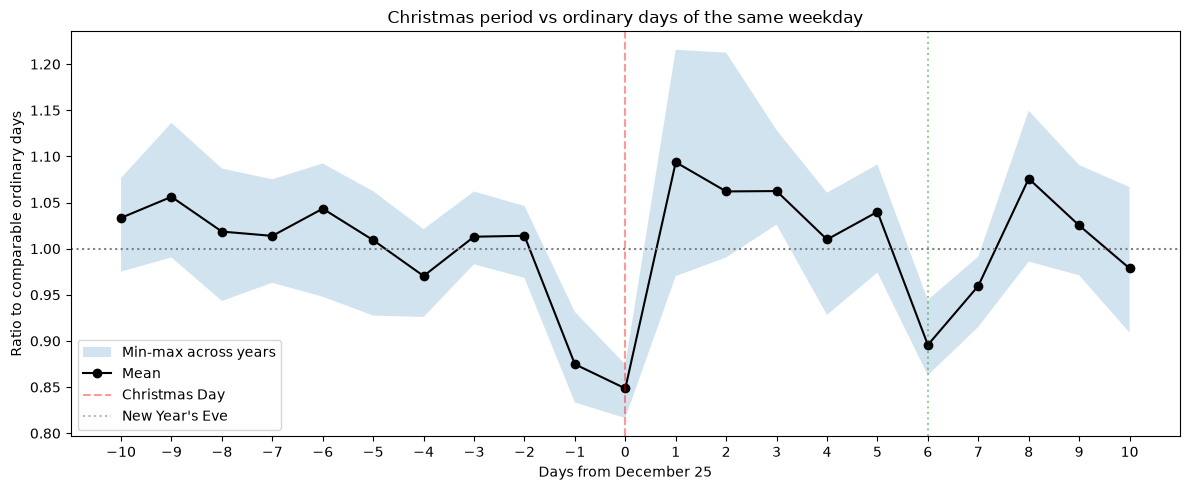

In [155]:
# 1. Special days to be excluded from the baseline
years = df.index.year.unique()
fr_holidays = holidays.France(years=range(years.min() - 1, years.max() + 2))
hol_dates = pd.DatetimeIndex(sorted(fr_holidays.keys()))
day_after = hol_dates + pd.Timedelta(days=1)

xmas_window = pd.DatetimeIndex([])
for y in range(years.min() - 1, years.max() + 1):
    xmas_window = xmas_window.union(pd.date_range(f"{y}-12-20", f"{y+1}-01-03"))

idx = df.index
special = idx.isin(hol_dates) | idx.isin(day_after) | idx.isin(xmas_window)
lockdown = (idx >= "2020-03-17") & (idx <= "2020-05-11")

# 2. Baseline: same weekday, one to four weeks before and after each date
ordinary = df["visits"].mask(special | lockdown)
shifts = [-28, -21, -14, -7, 7, 14, 21, 28]
neighbors = pd.concat([ordinary.shift(k) for k in shifts], axis=1)
df["baseline"] = neighbors.mean(axis=1).where(neighbors.count(axis=1) >= 4)


df["ratio_ordinary"] = df["visits"] / df["baseline"]
rows = []
for year in years:
    day = pd.Timestamp(year, 12, 25)
    if day in df.index:
        rows.append({
            "year": year,
            "weekday": day.day_name(),
            "visits": df.loc[day, "visits"],
            "baseline": round(df.loc[day, "baseline"], 1),
            "ratio": round(df.loc[day, "ratio_ordinary"], 3),
        })
xmas_table = pd.DataFrame(rows).set_index("year")

xmas_all = []
for year in years:
    xmas_day = pd.Timestamp(year, 12, 25)
    if xmas_day + pd.Timedelta(days=10) > df.index.max():
        continue
    s = df.loc[xmas_day - pd.Timedelta(days=10): xmas_day + pd.Timedelta(days=10), "ratio_ordinary"].copy()
    s.index = (s.index - xmas_day).days
    xmas_all.append(s.rename(year))
xmas_df = pd.concat(xmas_all, axis=1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(xmas_df.index, xmas_df.min(axis=1), xmas_df.max(axis=1), alpha=0.2, label="Min-max across years")
ax.plot(xmas_df.index, xmas_df.mean(axis=1), color="black", marker="o", label="Mean")
ax.axhline(1, color="grey", linestyle=":")
ax.axvline(0, color="red", linestyle="--", alpha=0.4, label="Christmas Day")
ax.axvline(6, color="green", linestyle=":", alpha=0.4, label="New Year's Eve")
ax.set_xticks(xmas_df.index)
ax.set_xlabel("Days from December 25")
ax.set_ylabel("Ratio to comparable ordinary days")
ax.set_title("Christmas period vs ordinary days of the same weekday")
ax.legend()
plt.tight_layout()
plt.show()


The black curve shows the average ratio across the five Christmas periods from 2017 to 2021. The shaded area spans the minimum and maximum ratios among those years; it is not a confidence interval. The 2022 Christmas period is omitted from this graph because the ten days after 25 December extend into 2023. The separate table includes 25 December 2022, for which a reference is available.

On average, 24 December is about 12.5% below its reference, and 25 December about 15% below. For 25 December, the six individual ratios in the table range from 0.816 to 0.875. The ratio rises to about 1.09 on 26 December. On 1 January, seven days after Christmas, the average ratio is about 0.96; on 2 January it is about 1.08.

These results describe differences in visits around the holidays. They do not show whether individual patients delayed a visit or establish that the calendar alone caused the differences. The shaded range and five yearly observations also do not prove that the pattern will recur every year.

We next examine 1 May, a public holiday in France. The comparison uses the same reference rule as above. It shows whether visits differ from nearby ordinary days falling on the same weekday.

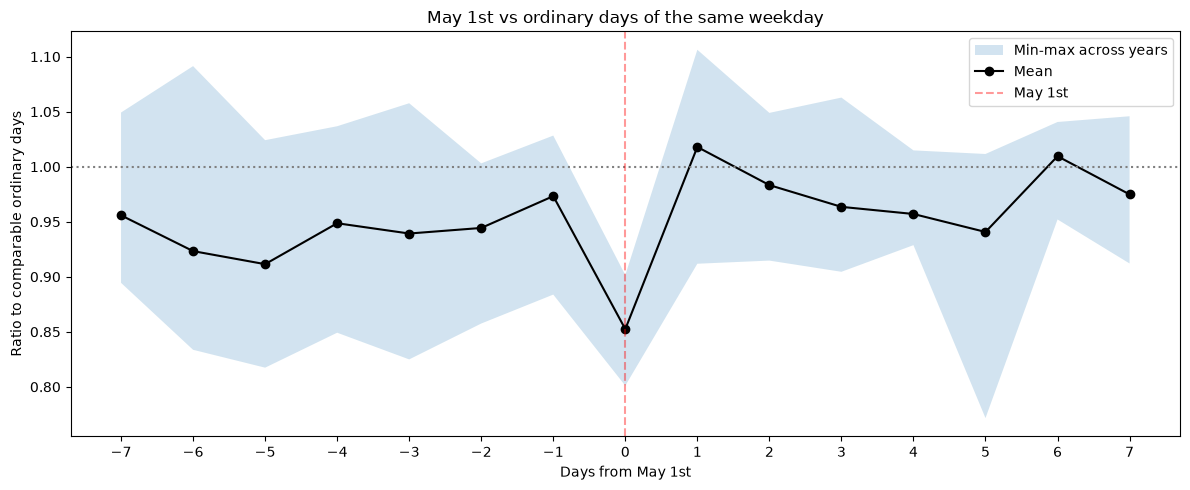

May 1 comparison by year (NaN means insufficient reference days):
        weekday  visits  baseline  ratio
year                                    
2017     Monday  1585.1    1963.9  0.807
2018    Tuesday  1499.2    1726.7  0.868
2019  Wednesday  1598.5    1773.1  0.902
2020     Friday   833.2       NaN    NaN
2021   Saturday  1261.7    1575.1  0.801
2022     Sunday  1397.5    1580.4  0.884

Number of years contributing to each day:
date
-7    5
-6    5
-5    5
-4    5
-3    5
-2    5
-1    5
 0    5
 1    5
 2    5
 3    5
 4    5
 5    6
 6    5
 7    5


In [154]:
years = df.index.year.unique()
fr_holidays = holidays.France(years=range(years.min() - 1, years.max() + 2))
hol_dates = pd.DatetimeIndex(sorted(fr_holidays.keys()))
day_after = hol_dates + pd.Timedelta(days=1)
xmas_window = pd.DatetimeIndex([])
for y in range(years.min() - 1, years.max() + 1):
    xmas_window = xmas_window.union(pd.date_range(f"{y}-12-20", f"{y+1}-01-03"))
idx = df.index
special = idx.isin(hol_dates) | idx.isin(day_after) | idx.isin(xmas_window)
lockdown = (idx >= "2020-03-17") & (idx <= "2020-05-11")
ordinary = df["visits"].mask(special | lockdown)
shifts = [-28, -21, -14, -7, 7, 14, 21, 28]
neighbors = pd.concat([ordinary.shift(k) for k in shifts], axis=1)
df["baseline"] = neighbors.mean(axis=1).where(neighbors.count(axis=1) >= 4)

df["ratio_ordinary"] = df["visits"] / df["baseline"]


name, month, day = "May 1st", 5, 1
window = 7
rows = []
for year in years:
    date = pd.Timestamp(year, month, day)
    if date in df.index:
        rows.append({
            "year": year,
            "weekday": date.day_name(),
            "visits": df.loc[date, "visits"],
            "baseline": round(df.loc[date, "baseline"], 1),
            "ratio": round(df.loc[date, "ratio_ordinary"], 3),
        })
holiday_table = pd.DataFrame(rows).set_index("year")

all_years = []
for year in years:
    center = pd.Timestamp(year, month, day)
    if center - pd.Timedelta(days=window) < df.index.min() or center + pd.Timedelta(days=window) > df.index.max():
        continue
    s = df.loc[center - pd.Timedelta(days=window): center + pd.Timedelta(days=window), "ratio_ordinary"].copy()
    s.index = (s.index - center).days
    all_years.append(s.rename(year))
h_df = pd.concat(all_years, axis=1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(h_df.index, h_df.min(axis=1), h_df.max(axis=1), alpha=0.2, label="Min-max across years")
ax.plot(h_df.index, h_df.mean(axis=1), color="black", marker="o", label="Mean")
ax.axhline(1, color="grey", linestyle=":")
ax.axvline(0, color="red", linestyle="--", alpha=0.4, label=name)
ax.set_xticks(h_df.index)
ax.set_xlabel(f"Days from {name}")
ax.set_ylabel("Ratio to comparable ordinary days")
ax.set_title(f"{name} vs ordinary days of the same weekday")
ax.legend()
plt.tight_layout()
plt.show()

print("May 1 comparison by year (NaN means insufficient reference days):")
print(holiday_table.to_string())
print("\nNumber of years contributing to each day:")
print(h_df.count(axis=1).rename("years").to_string())

For 1 May, the average ratio is approximately 0.85: visits are about 15% below the selected reference. This average includes five years: the 2020 reference is unavailable because the exclusion of the first lockdown leaves fewer than four comparable days. The ratios for the other five years range from about 0.80 to 0.90.

The number of years contributing to the curve can vary across the surrounding dates, so the shaded range should be read alongside the counts. The range describes the observed years, not uncertainty about future years. The comparison uses both earlier and later dates and does not establish that the holiday alone caused the difference.

Christmas and 1 May provide reasons to test calendar indicators in the forecasting models. Other public holidays and their following days may behave differently; their predictive value should be compared on the same dates and metrics before deciding which variables to retain. These descriptive findings do not establish an operational staffing requirement.